# Project 6: Irrelevant Variables and the Curse of Dimensionality

**Course:** MAC 312 — Foundations of Data Science

## 1. Theoretical Setup

### 1.1 Data-Generating Model
Each observation is $x = (z, u) \in \mathbb{R}^d$ with binary label $y \in \{0, 1\}$ and $P(y=0) = P(y=1) = 0.5$:
- Informative coordinates $z \in \mathbb{R}^r$:
  $$z \mid (y = 0) \sim \mathcal{N}(-\delta \mathbf{1}_r, \sigma_z^2 I_r), \qquad z \mid (y = 1) \sim \mathcal{N}(+\delta \mathbf{1}_r, \sigma_z^2 I_r)$$
- Irrelevant coordinates $u \in \mathbb{R}^{d-r}$:
  $$u \sim \mathcal{N}(0, \sigma_u^2 I_{d-r}), \qquad u \perp\!\!\!\perp (z, y)$$

Since $u$ is independent of $(z, y)$, the log-posterior odds depend only on $z$:
$$\log \frac{P(y = 1 \mid x)}{P(y = 0 \mid x)} = \frac{2\delta}{\sigma_z^2} \sum_{j=1}^r z_j$$

To keep classification difficulty constant across $r$, we set $\delta = \frac{\mu_0}{\sqrt{r}} \sigma_z$ with $\mu_0 = 1.2$. For $s(z) = \frac{1}{\sigma_z \sqrt{r}} \sum_{j=1}^r z_j$, we have $s(z) \mid (y=0) \sim \mathcal{N}(-\mu_0, 1)$ and $s(z) \mid (y=1) \sim \mathcal{N}(+\mu_0, 1)$, giving a constant Bayes optimal error rate of $\Phi(-\mu_0) = \Phi(-1.2) \approx 11.51\%$ for all $r$ and $\sigma_z$.

### 1.2 Distance Concentration
For two independent points $x = (z, u)$ and $x' = (z', u')$:
$$\|x - x'\|^2 = \|z - z'\|^2 + \|u - u'\|^2$$

Since $u_j - u'_j \sim \mathcal{N}(0, 2\sigma_u^2)$ independently:
$$\frac{\|u - u'\|^2}{2\sigma_u^2} \sim \chi^2(d - r) \implies \mathbb{E}[\|u - u'\|^2] = 2(d - r)\sigma_u^2, \qquad \operatorname{Var}(\|u - u'\|^2) = 8(d - r)\sigma_u^4$$

As $d$ grows, the relative spread shrinks as $\sqrt{2/d} \to 0$ and the distance contrast $C = (D_{\text{far}} - D_{\text{near}}) / D_{\text{near}} \to 0$.

### 1.3 Same-Class vs. Opposite-Class Distances
With $\delta = (\mu_0 / \sqrt{r})\sigma_z$:
- $\mathbb{E}[\|x - x'\|^2 \mid y = y'] = 2r\sigma_z^2 + 2(d - r)\sigma_u^2$
- $\mathbb{E}[\|x - x'\|^2 \mid y \neq y'] = 4\mu_0^2 \sigma_z^2 + 2r\sigma_z^2 + 2(d - r)\sigma_u^2$

The distance signal-to-noise ratio is:
$$\text{SNR}_{\text{dist}} = \frac{\mathbb{E}[\|x - x'\|^2 \mid y \neq y'] - \mathbb{E}[\|x - x'\|^2 \mid y = y']}{\sqrt{\operatorname{Var}(\|u - u'\|^2)}} = \frac{\sqrt{2}\,\mu_0^2}{\sqrt{d - r}} \left(\frac{\sigma_z}{\sigma_u}\right)^2$$

When $\text{SNR}_{\text{dist}} \ll 1$, noise fluctuations swamp the between-class gap $4\mu_0^2 \sigma_z^2$ and distance-based classifiers approach $50\%$ error.

### 1.4 Effect of Standardization
Marginal variances are $\operatorname{Var}(u_j) = \sigma_u^2$ and $\operatorname{Var}(z_j) = \sigma_z^2(1 + \mu_0^2/r)$. After standardizing every feature to unit variance, the between-class squared-distance gap becomes $\Delta_{\text{std}} = \frac{4\mu_0^2}{1 + \mu_0^2/r}$ regardless of $(\sigma_z, \sigma_u)$:
1. **Noise-Dominated ($\sigma_u \gg \sigma_z$):** Standardization removes the large noise scale, though $d - r$ unit-variance noise features remain.
2. **Equal-Scale ($\sigma_u = \sigma_z = 1$):** Dividing $z_j$ by $\sqrt{1 + \mu_0^2/r} > 1$ slightly shrinks the signal relative to noise ($\Delta_{\text{std}} \approx 3.35 < 5.76$).
3. **Signal-Dominated ($\sigma_z \gg \sigma_u$):** Standardization inflates small noise coordinates up to unit variance, hurting distance-based methods.

## 2. Setup

In [1]:
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cdist
from scipy.special import logsumexp
from scipy.stats import multivariate_normal, norm
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from tabulate import tabulate
from IPython.display import display

# Visual styling
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

# Global experiment settings (matching main.py --exp all --seeds 5)
N_SEEDS = 5
SIGNAL_NORM = 1.2
BAYES_ERROR = float(norm.cdf(-SIGNAL_NORM))
RESULTS_DIR = "results"
SAVE_ARTIFACTS = True  # Set False if you only want inline notebook outputs without writing files

COLORS = {
    "KNN": "#1f77b4",
    "GaussianKDE": "#ff7f0e",
    "Gaussian": "#2ca02c",
    "LogisticRegression": "#d62728",
}
MARKERS = {
    "KNN": "o",
    "GaussianKDE": "s",
    "Gaussian": "^",
    "LogisticRegression": "D",
}

print(f"Python executable : {sys.executable}")
print(f"Python version    : {sys.version.split()[0]}")
print(f"NumPy / Pandas    : {np.__version__} / {pd.__version__}")
print(f"Bayes Optimal Err : {BAYES_ERROR:.4f} ({BAYES_ERROR * 100:.2f}%)")

Python executable : /home/darkside/Documents/BITS/3-1/FDS/Project/-Irrelevant-variables-and-the-curse-of-dimensionality/venv/bin/python
Python version    : 3.14.4
NumPy / Pandas    : 2.5.5 / 3.1.1
Bayes Optimal Err : 0.1151 (11.51%)


## 3. Data Generation

Shapes        -> train: (500, 50), val: (500, 50), test: (1000, 50)
Class balance -> train P(y=1)=0.500, val=0.500, test=0.500
Missing/NaN   -> train=0, val=0, test=0


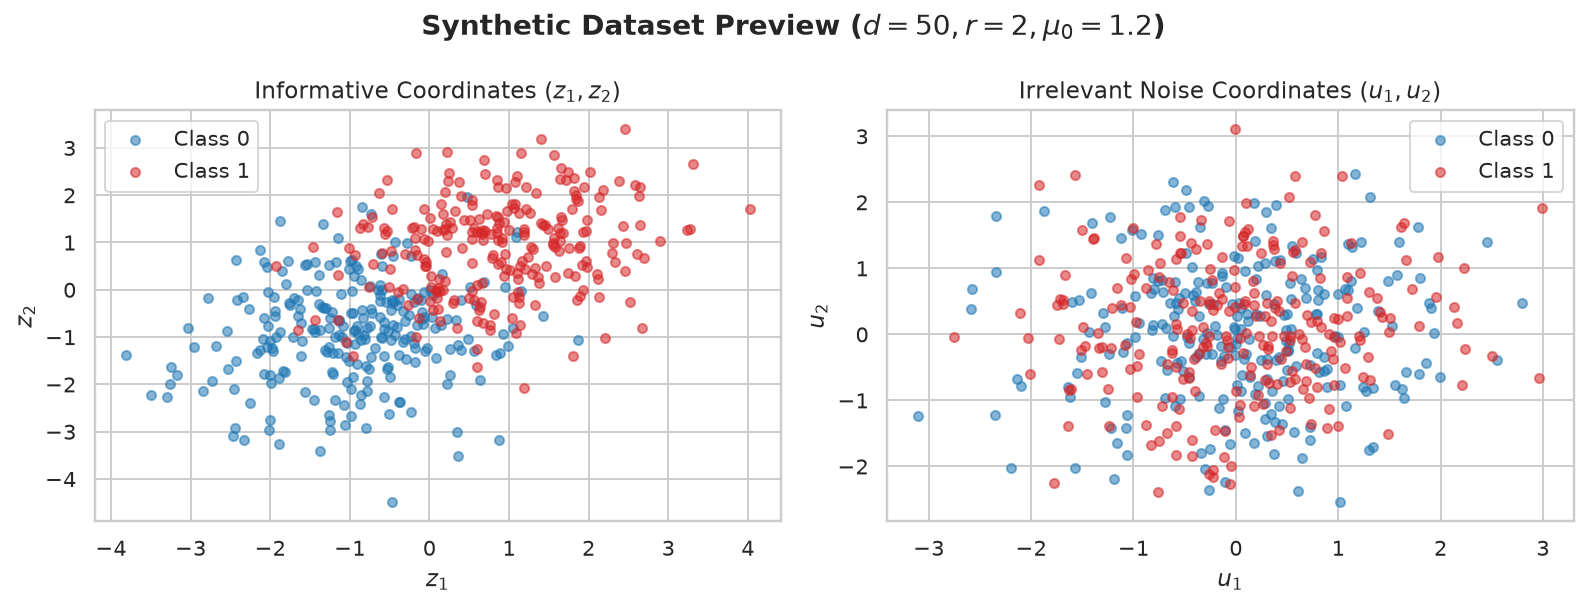

In [2]:
def generate_data(
    n_samples,
    d,
    r,
    signal_norm=1.2,
    informative_scale=1.0,
    noise_scale=1.0,
    rng=None,
):
    if rng is None:
        rng = np.random.default_rng()

    # Balanced binary labels: P(y=0) = P(y=1) = 0.5
    n0 = n_samples // 2
    y = np.array([0] * n0 + [1] * (n_samples - n0), dtype=int)
    rng.shuffle(y)

    # Scale per-coordinate shift by 1/sqrt(r) so total SNR (and Bayes error) stays
    # constant across informative dimension r and across rescaling of z
    delta = (signal_norm / np.sqrt(r)) * informative_scale
    sign = (2 * y - 1)[:, None]
    z = sign * delta + rng.normal(0.0, informative_scale, size=(n_samples, r))

    if d > r:
        u = rng.normal(0.0, noise_scale, size=(n_samples, d - r))
        X = np.hstack([z, u])
    else:
        X = z

    return X, y


def generate_splits(
    n_train,
    n_val,
    n_test,
    d,
    r,
    signal_norm=1.2,
    informative_scale=1.0,
    noise_scale=1.0,
    seed=42,
):
    # Separate RNGs so train, val, and test are independent and reproducible
    rng_train = np.random.default_rng(seed)
    rng_val = np.random.default_rng(seed + 10_000)
    rng_test = np.random.default_rng(seed + 20_000)

    X_train, y_train = generate_data(
        n_train, d, r, signal_norm, informative_scale, noise_scale, rng_train
    )
    X_val, y_val = generate_data(
        n_val, d, r, signal_norm, informative_scale, noise_scale, rng_val
    )
    X_test, y_test = generate_data(
        n_test, d, r, signal_norm, informative_scale, noise_scale, rng_test
    )

    return X_train, y_train, X_val, y_val, X_test, y_test


# Sanity check on a sample split (d=50, r=2)
X_tr_demo, y_tr_demo, X_va_demo, y_va_demo, X_te_demo, y_te_demo = generate_splits(
    500, 500, 1000, d=50, r=2, signal_norm=SIGNAL_NORM, seed=42
)
print(f"Shapes        -> train: {X_tr_demo.shape}, val: {X_va_demo.shape}, test: {X_te_demo.shape}")
print(f"Class balance -> train P(y=1)={y_tr_demo.mean():.3f}, val={y_va_demo.mean():.3f}, test={y_te_demo.mean():.3f}")
print(f"Missing/NaN   -> train={np.isnan(X_tr_demo).sum()}, val={np.isnan(X_va_demo).sum()}, test={np.isnan(X_te_demo).sum()}")

# Visualize informative (z1, z2) vs. irrelevant (u1, u2) coordinates
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), dpi=140)
for cls, color, label in [(0, "#1f77b4", "Class 0"), (1, "#d62728", "Class 1")]:
    mask = y_tr_demo == cls
    axes[0].scatter(X_tr_demo[mask, 0], X_tr_demo[mask, 1], alpha=0.55, s=22, color=color, label=label)
    axes[1].scatter(X_tr_demo[mask, 2], X_tr_demo[mask, 3], alpha=0.55, s=22, color=color, label=label)

axes[0].set_title("Informative Coordinates ($z_1, z_2$)")
axes[0].set_xlabel("$z_1$")
axes[0].set_ylabel("$z_2$")
axes[0].legend(frameon=True)

axes[1].set_title("Irrelevant Noise Coordinates ($u_1, u_2$)")
axes[1].set_xlabel("$u_1$")
axes[1].set_ylabel("$u_2$")
axes[1].legend(frameon=True)

fig.suptitle("Synthetic Dataset Preview ($d=50, r=2, \\mu_0=1.2$)", fontweight="bold")
plt.tight_layout()
plt.show()

## 4. Classifiers

In [3]:
class KNNClassifier:
    def __init__(self, n_neighbors=5):
        self.n_neighbors = n_neighbors

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y, dtype=int)
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        k = min(self.n_neighbors, len(self.y_train))
        dists = cdist(X, self.X_train, metric="euclidean")
        nn_idx = np.argpartition(dists, kth=k - 1, axis=1)[:, :k]
        p1 = np.mean(self.y_train[nn_idx] == 1, axis=1)
        return np.column_stack([1.0 - p1, p1])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


class GaussianKDEClassifier:
    def __init__(self, bandwidth=1.0):
        self.bandwidth = bandwidth

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)
        self.d = X.shape[1]
        self.X_class = [X[y == 0], X[y == 1]]
        self.priors = [len(self.X_class[0]) / len(y), len(self.X_class[1]) / len(y)]
        return self

    def _class_log_density(self, X, c):
        Xc = self.X_class[c]
        h = self.bandwidth
        dist_sq = cdist(X, Xc, metric="sqeuclidean")
        # Compute in log-space to avoid floating-point underflow in high d
        log_kernel_sum = logsumexp(-dist_sq / (2.0 * h * h), axis=1)
        log_norm = -np.log(len(Xc)) - 0.5 * self.d * np.log(2.0 * np.pi) - self.d * np.log(h)
        return log_norm + log_kernel_sum

    def predict_log_proba(self, X):
        X = np.asarray(X, dtype=float)
        log_p0 = self._class_log_density(X, 0) + np.log(self.priors[0])
        log_p1 = self._class_log_density(X, 1) + np.log(self.priors[1])
        joint = np.column_stack([log_p0, log_p1])
        return joint - logsumexp(joint, axis=1, keepdims=True)

    def predict_proba(self, X):
        return np.exp(self.predict_log_proba(X))

    def predict(self, X):
        lp = self.predict_log_proba(X)
        return (lp[:, 1] >= lp[:, 0]).astype(int)


class GaussianClassifier:
    def __init__(self, alpha=0.1):
        self.alpha = alpha

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)
        d = X.shape[1]
        self.priors = [np.mean(y == 0), np.mean(y == 1)]
        self.means = []
        self.covs = []

        for c in (0, 1):
            Xc = X[y == c]
            mu = Xc.mean(axis=0)
            S = np.cov(Xc, rowvar=False) if d > 1 else np.array([[np.var(Xc, ddof=1)]])
            # Shrink sample covariance toward an isotropic diagonal matrix
            avg_var = np.trace(S) / d
            cov = (1.0 - self.alpha) * S + self.alpha * avg_var * np.eye(d) + 1e-6 * np.eye(d)
            self.means.append(mu)
            self.covs.append(cov)
        return self

    def predict_log_proba(self, X):
        X = np.asarray(X, dtype=float)
        log_p0 = multivariate_normal.logpdf(X, mean=self.means[0], cov=self.covs[0]) + np.log(self.priors[0])
        log_p1 = multivariate_normal.logpdf(X, mean=self.means[1], cov=self.covs[1]) + np.log(self.priors[1])
        joint = np.column_stack([log_p0, log_p1])
        return joint - logsumexp(joint, axis=1, keepdims=True)

    def predict_proba(self, X):
        return np.exp(self.predict_log_proba(X))

    def predict(self, X):
        lp = self.predict_log_proba(X)
        return (lp[:, 1] >= lp[:, 0]).astype(int)


class LogisticRegressionClassifier:
    def __init__(self, C=1.0, max_iter=2000):
        self.C = C
        self.model = LogisticRegression(C=C, solver="lbfgs", max_iter=max_iter)

    def fit(self, X, y):
        self.model.fit(X, y)
        return self

    def predict_proba(self, X):
        return self.model.predict_proba(X)

    def predict(self, X):
        return self.model.predict(X).astype(int)

### Preprocessing

In [4]:
class RawTransformer:
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)


class Standardizer:
    def __init__(self):
        self.scaler = StandardScaler()

    def fit(self, X, y=None):
        self.scaler.fit(X)
        return self

    def transform(self, X):
        return self.scaler.transform(X)


class FeatureWeighter:
    """Standardize features, then weight each coordinate by its training ANOVA F-score."""

    def __init__(self):
        self.scaler = StandardScaler()
        self.weights = None

    def fit(self, X, y):
        X_std = self.scaler.fit_transform(X)
        f_vals, _ = f_classif(X_std, y)
        f_vals = np.nan_to_num(f_vals, nan=1e-4, posinf=1e4, neginf=1e-4)
        f_vals = np.maximum(f_vals, 1e-4)
        # Normalize weights so average weight is 1
        self.weights = (f_vals / np.sum(f_vals)) * X.shape[1]
        return self

    def transform(self, X):
        return self.scaler.transform(X) * np.sqrt(self.weights)


class FeatureSelector:
    """Training-only top-k feature selection via ANOVA F-score (after standardization)."""

    def __init__(self, k_features=2):
        self.k_features = k_features
        self.scaler = StandardScaler()
        self.selector = SelectKBest(score_func=f_classif, k=k_features)

    def fit(self, X, y):
        X_std = self.scaler.fit_transform(X)
        self.selector.set_params(k=min(self.k_features, X.shape[1]))
        self.selector.fit(X_std, y)
        return self

    def transform(self, X):
        return self.selector.transform(self.scaler.transform(X))


class OracleSelector:
    """Diagnostic baseline using only the true informative coordinates z."""

    def __init__(self, r=2):
        self.r = r

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return np.asarray(X[:, : self.r], dtype=float)

### Distance Metrics, Evaluation & Plotting

In [5]:
CLASSIFIERS = ["KNN", "GaussianKDE", "Gaussian", "LogisticRegression"]

PARAM_GRIDS = {
    "KNN": [1, 3, 5, 7, 11, 15, 21, 31, 51],
    "GaussianKDE": [0.2, 0.5, 1.0, 2.0, 3.0, 5.0, 10.0, 20.0, 50.0, 100.0],
    "Gaussian": [0.0, 0.01, 0.05, 0.1, 0.2, 0.5, 0.8, 1.0],
    "LogisticRegression": [1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0, 100.0],
}


def compute_distance_metrics(X_test, X_train, eps=1e-12):
    dists = cdist(X_test, X_train, metric="euclidean")
    d_near = np.min(dists, axis=1)
    d_far = np.max(dists, axis=1)

    contrast = (d_far - d_near) / np.maximum(d_near, eps)
    ratio = d_near / np.maximum(d_far, eps)

    return {
        "mean_d_near": float(np.mean(d_near)),
        "mean_d_far": float(np.mean(d_far)),
        "mean_contrast": float(np.mean(contrast)),
        "mean_ratio": float(np.mean(ratio)),
    }


def error_rate(y_true, y_pred):
    return float(np.mean(np.asarray(y_true) != np.asarray(y_pred)))


def log_loss(y_true, y_prob, eps=1e-15):
    y_true = np.asarray(y_true, dtype=float)
    y_prob = np.asarray(y_prob, dtype=float)
    p1 = y_prob[:, 1] if y_prob.ndim == 2 else y_prob
    p1 = np.clip(p1, eps, 1.0 - eps)
    return float(-np.mean(y_true * np.log(p1) + (1.0 - y_true) * np.log(1.0 - p1)))


def make_classifier(name, param):
    if name == "KNN":
        return KNNClassifier(n_neighbors=int(param))
    if name == "GaussianKDE":
        return GaussianKDEClassifier(bandwidth=float(param))
    if name == "Gaussian":
        return GaussianClassifier(alpha=float(param))
    if name == "LogisticRegression":
        return LogisticRegressionClassifier(C=float(param))
    raise ValueError(f"Unknown classifier: {name}")


def tune_classifier(name, X_train, y_train, X_val, y_val):
    best_model = None
    best_param = None
    best_val_err = float("inf")
    best_val_loss = float("inf")

    for val in PARAM_GRIDS[name]:
        param = min(int(val), len(y_train)) if name == "KNN" else val
        model = make_classifier(name, param).fit(X_train, y_train)

        val_err = error_rate(y_val, model.predict(X_val))
        val_loss = log_loss(y_val, model.predict_proba(X_val))

        if name == "KNN":
            better = (val_err < best_val_err - 1e-9) or (
                abs(val_err - best_val_err) <= 1e-9 and val_loss < best_val_loss
            )
        else:
            better = val_loss < best_val_loss

        if better:
            best_model = model
            best_param = param
            best_val_err = val_err
            best_val_loss = val_loss

    return best_model, best_param, best_val_err, best_val_loss


def evaluate_classifier(name, X_train, y_train, X_val, y_val, X_test, y_test, dist_metrics=None):
    model, best_param, val_err, val_loss = tune_classifier(name, X_train, y_train, X_val, y_val)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)

    if dist_metrics is None:
        dist_metrics = compute_distance_metrics(X_test, X_train)

    return {
        "classifier": name,
        "error_rate": error_rate(y_test, y_pred),
        "log_loss": log_loss(y_test, y_prob),
        "best_param": best_param,
        "val_error": val_err,
        "val_loss": val_loss,
        **dist_metrics,
    }


def summarize_results(raw_df, group_cols):
    metrics = ["error_rate", "log_loss", "mean_d_near", "mean_d_far", "mean_contrast", "mean_ratio"]
    agg = {}
    for col in metrics:
        agg[f"{col}_mean"] = (col, "mean")
        agg[f"{col}_std"] = (col, "std")
    return raw_df.groupby(group_cols).agg(**agg).reset_index()


def save_results(raw_df, summary_df, exp_name, results_dir=RESULTS_DIR):
    if not SAVE_ARTIFACTS:
        return
    csv_dir = os.path.join(results_dir, "csv")
    tables_dir = os.path.join(results_dir, "tables")
    os.makedirs(csv_dir, exist_ok=True)
    os.makedirs(tables_dir, exist_ok=True)

    raw_df.to_csv(os.path.join(csv_dir, f"{exp_name}_raw.csv"), index=False)
    summary_df.to_csv(os.path.join(csv_dir, f"{exp_name}_summary.csv"), index=False)

    md = tabulate(summary_df.round(4), headers="keys", tablefmt="pipe", showindex=False)
    with open(os.path.join(tables_dir, f"{exp_name}_table.md"), "w", encoding="utf-8") as f:
        f.write(f"# {exp_name}\n\n{md}\n")


def format_compact_table(summary_df, index_cols):
    out = summary_df[index_cols].copy()
    out["Error (Mean ± Std)"] = summary_df.apply(
        lambda row: f"{row['error_rate_mean']:.4f} ± {row['error_rate_std']:.4f}", axis=1
    )
    out["Log-Loss (Mean ± Std)"] = summary_df.apply(
        lambda row: f"{row['log_loss_mean']:.4f} ± {row['log_loss_std']:.4f}", axis=1
    )
    out["D_near"] = summary_df["mean_d_near_mean"].round(3)
    out["D_far"] = summary_df["mean_d_far_mean"].round(3)
    out["Contrast C"] = summary_df["mean_contrast_mean"].round(3)
    return out

In [6]:
def plot_curves(
    summary_df,
    x_col,
    y_mean,
    y_std,
    x_label,
    y_label,
    title,
    save_path=None,
    log_x=False,
    ylim=None,
    hline=None,
    hline_label=None,
):
    fig, ax = plt.subplots(figsize=(7.8, 4.8), dpi=150)

    for clf, group in summary_df.groupby("classifier"):
        g = group.sort_values(x_col)
        x = g[x_col].values
        mean = g[y_mean].values
        std = g[y_std].values
        c = COLORS.get(clf)
        ax.plot(x, mean, marker=MARKERS.get(clf, "o"), label=clf, color=c, linewidth=2)
        ax.fill_between(x, mean - std, mean + std, color=c, alpha=0.16)

    if hline is not None:
        ax.axhline(hline, color="black", linestyle="--", linewidth=1.2, label=hline_label)

    if log_x:
        ax.set_xscale("log")
    if ylim is not None:
        ax.set_ylim(ylim)

    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_title(title)
    ax.legend(frameon=True)
    plt.tight_layout()
    if SAVE_ARTIFACTS and save_path:
        os.makedirs(os.path.dirname(os.path.abspath(save_path)), exist_ok=True)
        fig.savefig(save_path, dpi=200)
    plt.show()


def plot_distance_summary(summary_df, x_col, x_label, title, save_path=None, log_x=False):
    fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.3), dpi=150)

    sub = summary_df[summary_df["classifier"] == summary_df["classifier"].iloc[0]].sort_values(x_col)
    x = sub[x_col].values

    panels = [
        ("mean_d_near", "Mean Nearest Distance ($D_{near}$)", "Nearest Distance", "#1f77b4", "o"),
        ("mean_d_far", "Mean Farthest Distance ($D_{far}$)", "Farthest Distance", "#ff7f0e", "s"),
        ("mean_contrast", "Contrast $(D_{far} - D_{near}) / D_{near}$", "Distance Contrast", "#2ca02c", "^"),
    ]
    for ax, (col, ylabel, ptitle, color, marker) in zip(axes, panels):
        m = sub[f"{col}_mean"].values
        s = sub[f"{col}_std"].values
        ax.plot(x, m, marker=marker, color=color, linewidth=2)
        ax.fill_between(x, m - s, m + s, color=color, alpha=0.18)
        if log_x:
            ax.set_xscale("log")
        ax.set_xlabel(x_label)
        ax.set_ylabel(ylabel)
        ax.set_title(ptitle)

    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    if SAVE_ARTIFACTS and save_path:
        os.makedirs(os.path.dirname(os.path.abspath(save_path)), exist_ok=True)
        fig.savefig(save_path, dpi=200)
    plt.show()


def plot_scale_regimes(summary_df, metric_mean, metric_std, y_label, title, save_path=None):
    regimes = ["Noise-Dominated", "Equal-Scale", "Signal-Dominated"]
    settings = ["Raw", "Standardized", "Weighted", "Selected", "Oracle"]
    classifiers = ["KNN", "GaussianKDE", "Gaussian", "LogisticRegression"]
    palette = sns.color_palette("muted", len(settings))

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), dpi=150, sharey=True)
    x = np.arange(len(classifiers))
    width = 0.8 / len(settings)

    for ax, regime in zip(axes, regimes):
        rdf = summary_df[summary_df["regime"] == regime]
        for i, setting in enumerate(settings):
            sdf = rdf[rdf["setting"] == setting].set_index("classifier")
            means = [sdf.loc[c, metric_mean] for c in classifiers]
            stds = [sdf.loc[c, metric_std] for c in classifiers]
            offset = (i - len(settings) / 2 + 0.5) * width
            ax.bar(
                x + offset,
                means,
                width=width,
                yerr=stds,
                label=setting,
                color=palette[i],
                capsize=2.5,
                edgecolor="black",
                linewidth=0.6,
            )
        ax.set_xticks(x)
        ax.set_xticklabels(["KNN", "KDE", "Gaussian", "LogReg"])
        ax.set_title(regime)

    axes[0].set_ylabel(y_label)
    axes[-1].legend(title="Pipeline", loc="upper right", fontsize=8.5)
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    if SAVE_ARTIFACTS and save_path:
        os.makedirs(os.path.dirname(os.path.abspath(save_path)), exist_ok=True)
        fig.savefig(save_path, dpi=200)
    plt.show()


def plot_paired_informative_dim(summary_df, y_mean, y_std, y_label, title, save_path=None, hline=None):
    modes = ["Fixed Ambient (d=50)", "No Noise (d=r)"]
    fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.7), dpi=150, sharey=True)

    for ax, mode in zip(axes, modes):
        mdf = summary_df[summary_df["mode"] == mode]
        for clf, group in mdf.groupby("classifier"):
            g = group.sort_values("r")
            x = g["r"].values
            m = g[y_mean].values
            s = g[y_std].values
            c = COLORS.get(clf)
            ax.plot(x, m, marker=MARKERS.get(clf, "o"), label=clf, color=c, linewidth=2)
            ax.fill_between(x, m - s, m + s, color=c, alpha=0.16)
        if hline is not None:
            ax.axhline(hline, color="black", linestyle="--", linewidth=1.2, label="Bayes Optimal")
        ax.set_xlabel("Informative Dimension ($r$)")
        ax.set_title(mode)
        ax.legend(frameon=True, fontsize=8.5)

    axes[0].set_ylabel(y_label)
    fig.suptitle(title, fontweight="bold")
    plt.tight_layout()
    if SAVE_ARTIFACTS and save_path:
        os.makedirs(os.path.dirname(os.path.abspath(save_path)), exist_ok=True)
        fig.savefig(save_path, dpi=200)
    plt.show()

## 5. Experiment 1: Increasing Ambient Dimension ($d$)
Fixed: $r = 2$, $n_{\text{train}} = 500$, $n_{\text{val}} = 500$, $n_{\text{test}} = 1000$, $\sigma_z = \sigma_u = 1.0$, $\mu_0 = 1.2$.
Varied: $d \in \{2, 5, 10, 20, 50, 100, 200\}$ over 5 seeds.

In [7]:
t0 = time.time()
d_list = [2, 5, 10, 20, 50, 100, 200]
r_exp1 = 2
n_train_1, n_val_1, n_test_1 = 500, 500, 1000

rows_exp1 = []
for d in d_list:
    for s in range(N_SEEDS):
        seed = 42 + s
        X_tr, y_tr, X_va, y_va, X_te, y_te = generate_splits(
            n_train_1, n_val_1, n_test_1, d=d, r=r_exp1, signal_norm=SIGNAL_NORM, seed=seed
        )
        dist_metrics = compute_distance_metrics(X_te, X_tr)

        for clf in CLASSIFIERS:
            res = evaluate_classifier(clf, X_tr, y_tr, X_va, y_va, X_te, y_te, dist_metrics)
            res.update({"d": d, "r": r_exp1, "n_train": n_train_1, "seed": seed})
            rows_exp1.append(res)

exp1_raw = pd.DataFrame(rows_exp1)
exp1_summary = summarize_results(exp1_raw, ["d", "classifier"])
save_results(exp1_raw, exp1_summary, "experiment_1_ambient_dimension", RESULTS_DIR)

print(f"Experiment 1 finished in {time.time() - t0:.1f}s")
display(format_compact_table(exp1_summary, ["d", "classifier"]))

Experiment 1 finished in 73.5s


,d,classifier,Error (Mean ± Std),Log-Loss (Mean ± Std),D_near,D_far,Contrast C
0,2,Gaussian,0.1132 ± 0.0051,0.2710 ± 0.0085,0.130,5.695,84.151
1,2,GaussianKDE,0.1140 ± 0.0048,0.2798 ± 0.0114,0.130,5.695,84.151
2,2,KNN,0.1174 ± 0.0044,0.4623 ± 0.2610,0.130,5.695,84.151
3,2,LogisticRegression,0.1132 ± 0.0061,0.2712 ± 0.0085,0.130,5.695,84.151
4,5,Gaussian,0.1144 ± 0.0072,0.2712 ± 0.0089,0.880,6.598,7.417
5,5,GaussianKDE,0.1182 ± 0.0037,0.3154 ± 0.0153,0.880,6.598,7.417
6,5,KNN,0.1220 ± 0.0074,0.3395 ± 0.0555,0.880,6.598,7.417
7,5,LogisticRegression,0.1170 ± 0.0058,0.2753 ± 0.0072,0.880,6.598,7.417
8,10,Gaussian,0.1180 ± 0.0049,0.2748 ± 0.0095,2.049,7.509,2.785
9,10,GaussianKDE,0.1282 ± 0.0132,0.3359 ± 0.0095,2.049,7.509,2.785


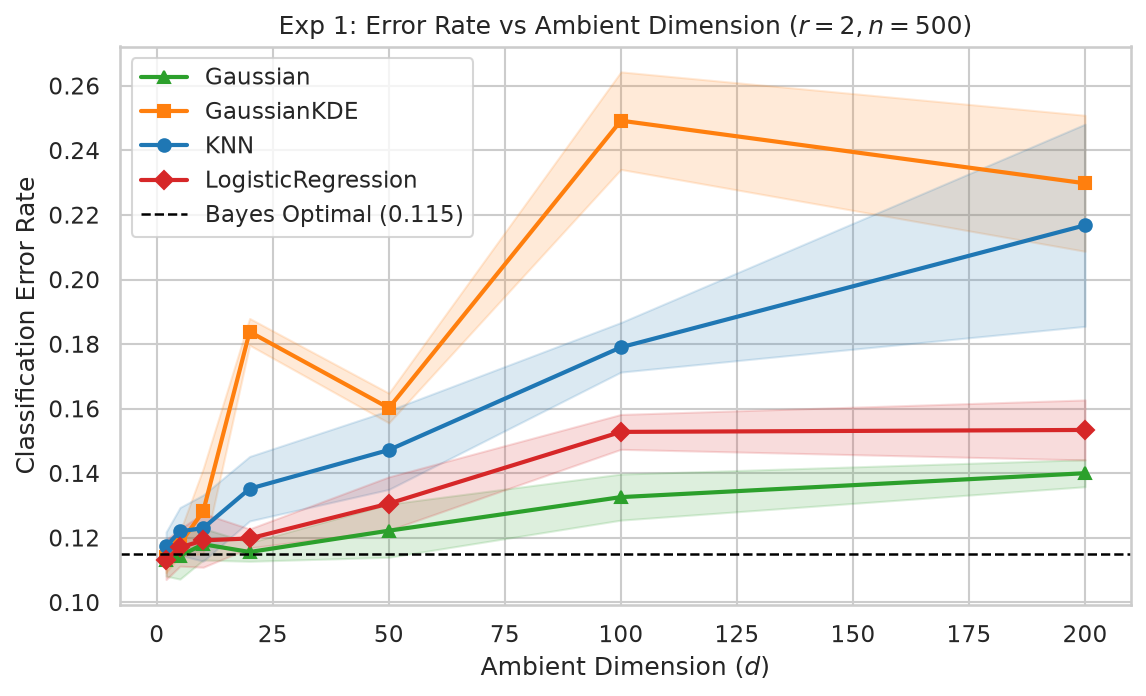

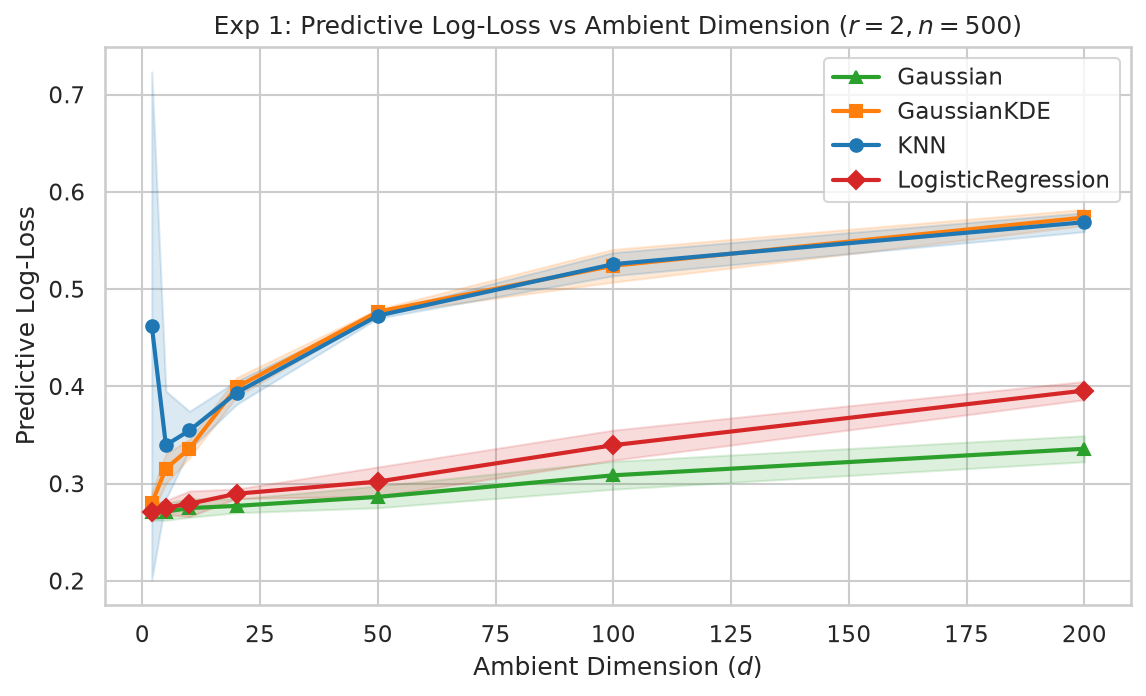

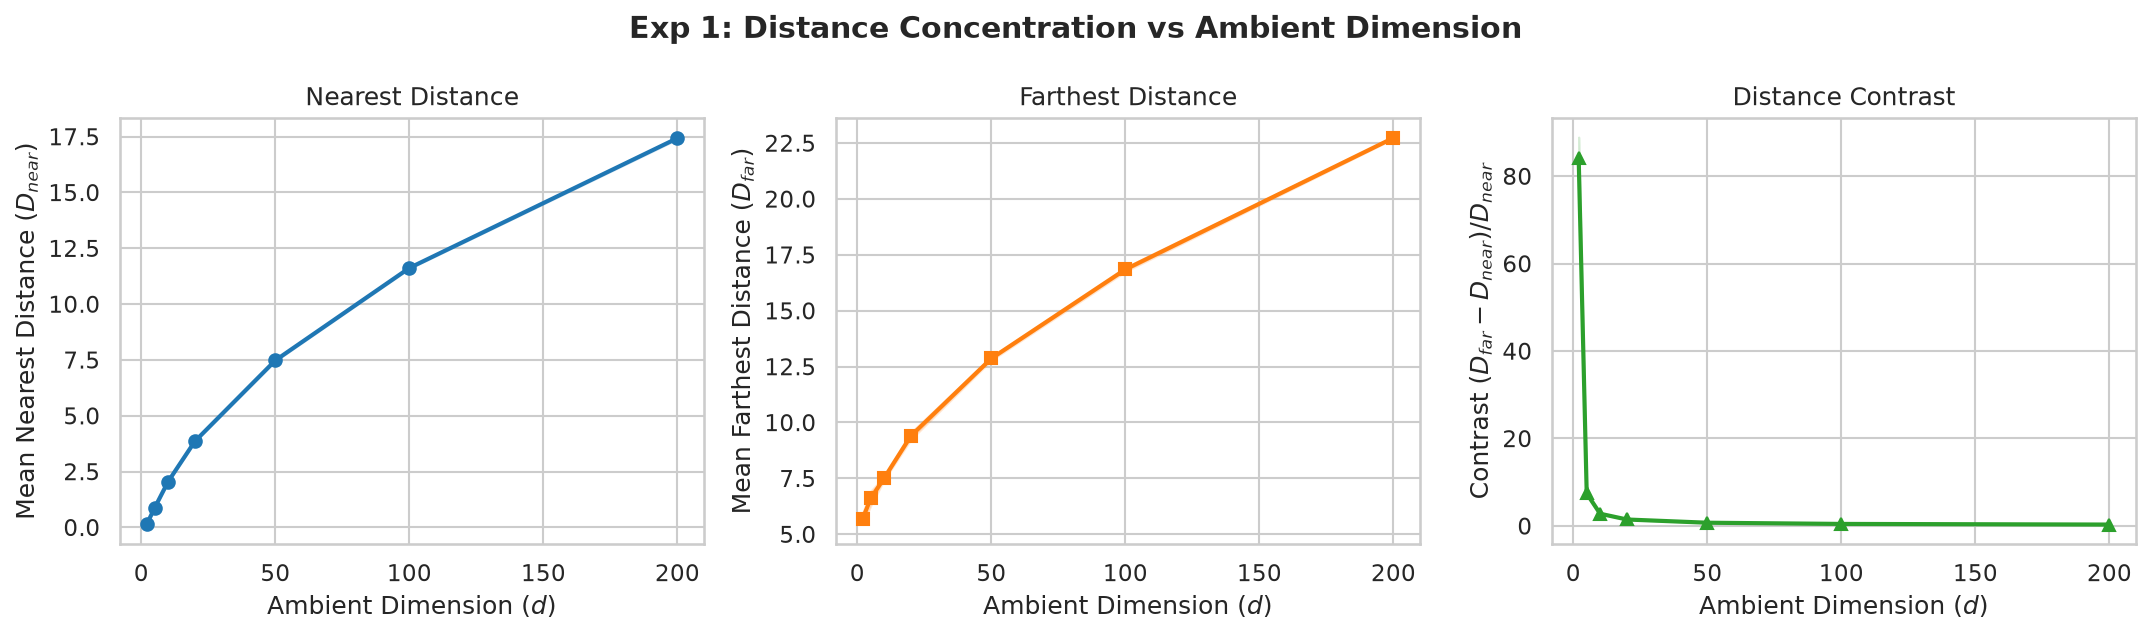

In [8]:
plots_dir = os.path.join(RESULTS_DIR, "plots")

plot_curves(
    exp1_summary, "d", "error_rate_mean", "error_rate_std",
    x_label="Ambient Dimension ($d$)",
    y_label="Classification Error Rate",
    title="Exp 1: Error Rate vs Ambient Dimension ($r=2, n=500$)",
    save_path=os.path.join(plots_dir, "exp1_error_vs_ambient_dim.png"),
    hline=BAYES_ERROR, hline_label=f"Bayes Optimal ({BAYES_ERROR:.3f})",
)

plot_curves(
    exp1_summary, "d", "log_loss_mean", "log_loss_std",
    x_label="Ambient Dimension ($d$)",
    y_label="Predictive Log-Loss",
    title="Exp 1: Predictive Log-Loss vs Ambient Dimension ($r=2, n=500$)",
    save_path=os.path.join(plots_dir, "exp1_log_loss_vs_ambient_dim.png"),
)

plot_distance_summary(
    exp1_summary, "d",
    x_label="Ambient Dimension ($d$)",
    title="Exp 1: Distance Concentration vs Ambient Dimension",
    save_path=os.path.join(plots_dir, "exp1_distance_concentration.png"),
)

### Analysis
- Increasing $d$ from $2$ to $200$ pushes $D_{\text{near}}$ from $0.130$ to $17.430$ (roughly $\sqrt{2d}$) and drops distance contrast $C$ from $84.15$ to $0.305$.
- At $d=2$, all four classifiers are near the $11.51\%$ Bayes error. By $d=200$, KNN rises to $21.68\%$ error (log-loss $0.569$) and Gaussian KDE rises to $22.98\%$ (log-loss $0.574$).
- Regularized Gaussian ($14.00\%$ error, log-loss $0.336$) and L2 Logistic Regression ($15.34\%$ error, log-loss $0.396$) degrade much more slowly because covariance shrinkage and L2 regularization down-weight irrelevant features.
- At $d=2$, KNN shows higher log-loss variance despite low error because neighbor fractions $m/k$ can hit $0$ or $1$ for small $k$.

## 6. Experiment 2: Increasing Sample Size ($n$)
Fixed: $r = 2$, $d = 50$, $n_{\text{val}} = 500$, $n_{\text{test}} = 1000$, $\sigma_z = \sigma_u = 1.0$, $\mu_0 = 1.2$.
Varied: $n_{\text{train}} \in \{100, 250, 500, 1000, 2500, 5000\}$ over 5 seeds.

In [9]:
t0 = time.time()
n_list = [100, 250, 500, 1000, 2500, 5000]
d_exp2, r_exp2 = 50, 2
n_val_2, n_test_2 = 500, 1000

rows_exp2 = []
for n_train in n_list:
    for s in range(N_SEEDS):
        seed = 42 + s
        X_tr, y_tr, X_va, y_va, X_te, y_te = generate_splits(
            n_train, n_val_2, n_test_2, d=d_exp2, r=r_exp2, signal_norm=SIGNAL_NORM, seed=seed
        )
        dist_metrics = compute_distance_metrics(X_te, X_tr)

        for clf in CLASSIFIERS:
            res = evaluate_classifier(clf, X_tr, y_tr, X_va, y_va, X_te, y_te, dist_metrics)
            res.update({"n_train": n_train, "d": d_exp2, "r": r_exp2, "seed": seed})
            rows_exp2.append(res)

exp2_raw = pd.DataFrame(rows_exp2)
exp2_summary = summarize_results(exp2_raw, ["n_train", "classifier"])
save_results(exp2_raw, exp2_summary, "experiment_2_sample_size", RESULTS_DIR)

print(f"Experiment 2 finished in {time.time() - t0:.1f}s")
display(format_compact_table(exp2_summary, ["n_train", "classifier"]))

Experiment 2 finished in 44.7s


,n_train,classifier,Error (Mean ± Std),Log-Loss (Mean ± Std),D_near,D_far,Contrast C
0,100,Gaussian,0.1504 ± 0.0054,0.3522 ± 0.0065,7.895,12.344,0.568
1,100,GaussianKDE,0.2388 ± 0.0388,0.5176 ± 0.0377,7.895,12.344,0.568
2,100,KNN,0.1884 ± 0.0226,0.5710 ± 0.0167,7.895,12.344,0.568
3,100,LogisticRegression,0.1626 ± 0.0136,0.3777 ± 0.0229,7.895,12.344,0.568
4,250,Gaussian,0.1262 ± 0.0068,0.3003 ± 0.0063,7.651,12.631,0.655
5,250,GaussianKDE,0.1738 ± 0.0077,0.4835 ± 0.0119,7.651,12.631,0.655
6,250,KNN,0.1506 ± 0.0102,0.5089 ± 0.0078,7.651,12.631,0.655
7,250,LogisticRegression,0.1412 ± 0.0081,0.3208 ± 0.0101,7.651,12.631,0.655
8,500,Gaussian,0.1222 ± 0.0082,0.2863 ± 0.0112,7.477,12.863,0.725
9,500,GaussianKDE,0.1602 ± 0.0046,0.4767 ± 0.0025,7.477,12.863,0.725


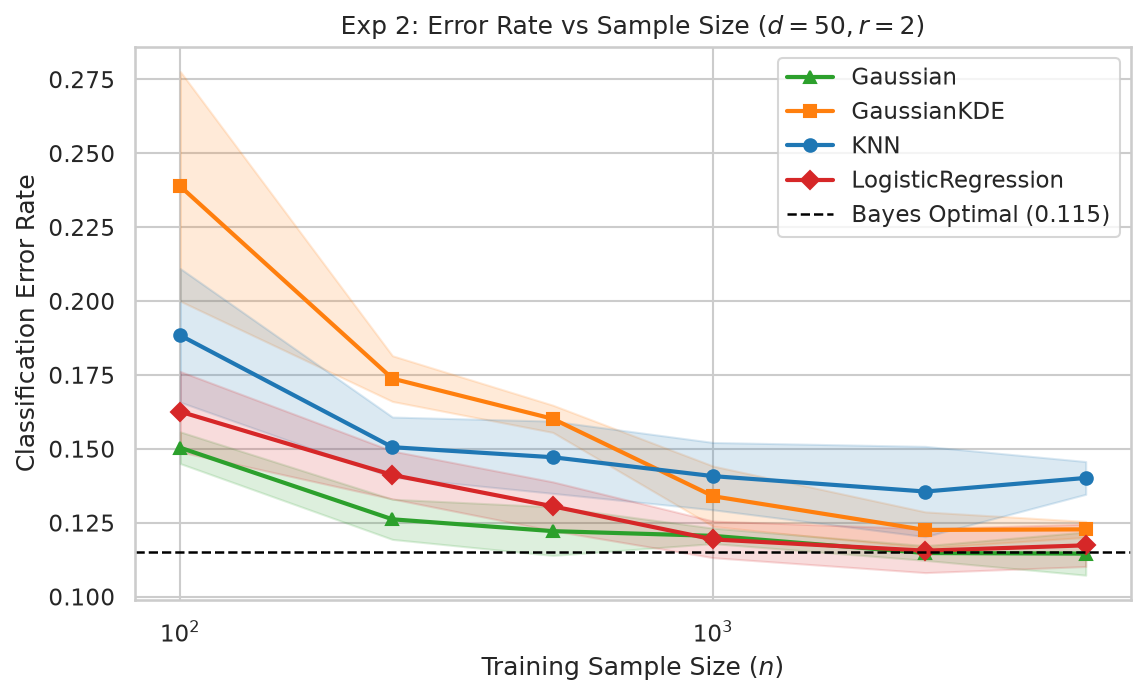

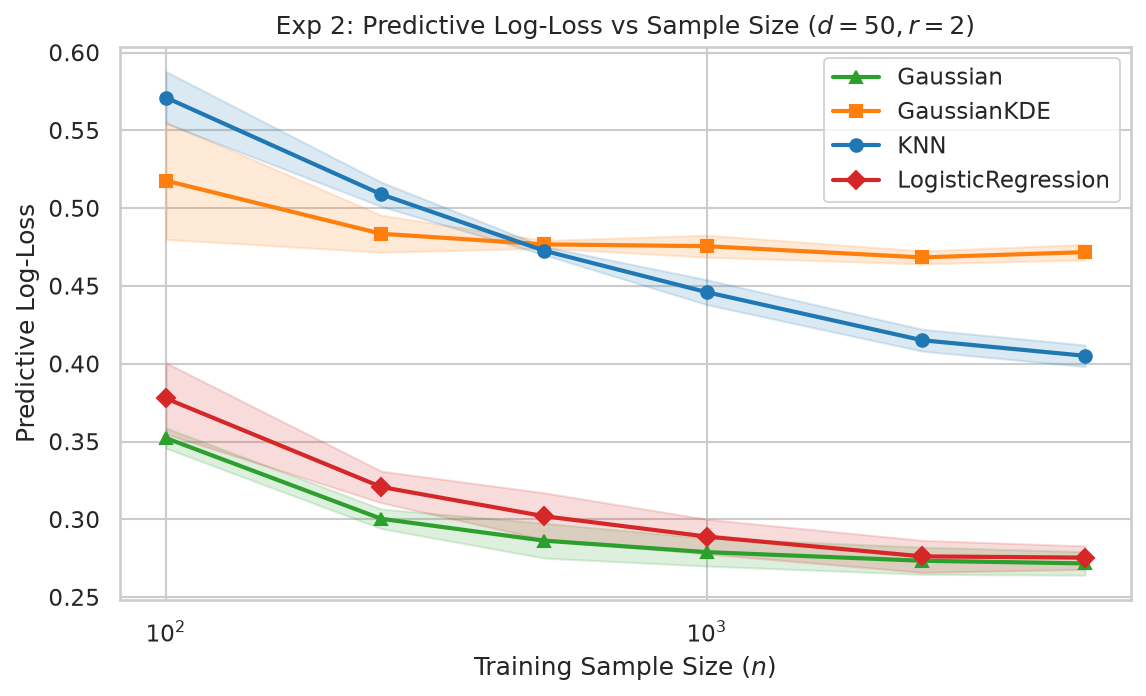

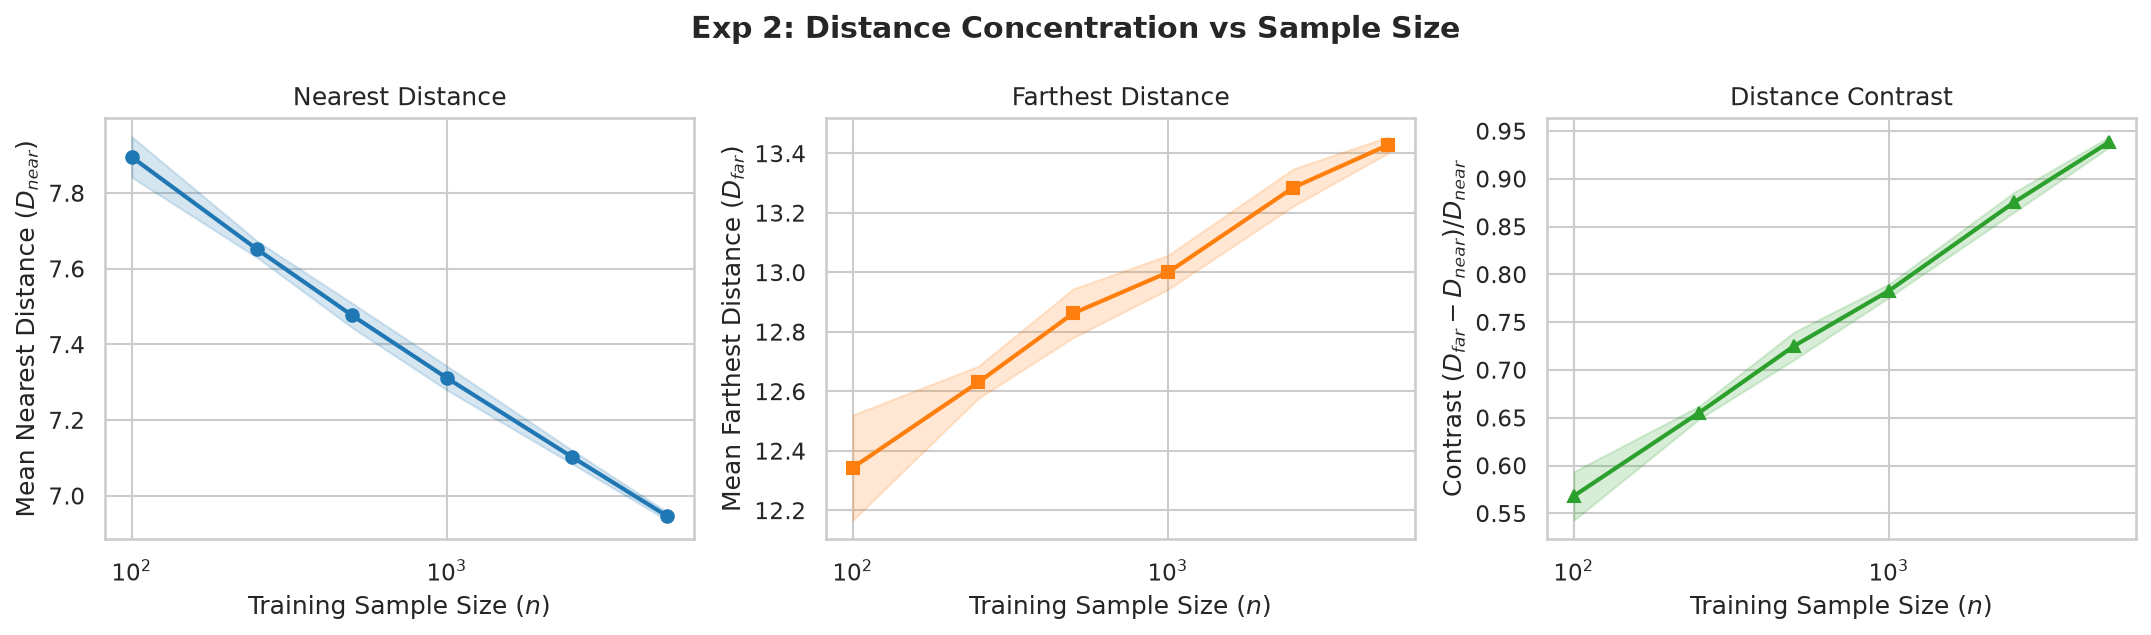

In [10]:
plot_curves(
    exp2_summary, "n_train", "error_rate_mean", "error_rate_std",
    x_label="Training Sample Size ($n$)",
    y_label="Classification Error Rate",
    title="Exp 2: Error Rate vs Sample Size ($d=50, r=2$)",
    save_path=os.path.join(plots_dir, "exp2_error_vs_sample_size.png"),
    log_x=True,
    hline=BAYES_ERROR, hline_label=f"Bayes Optimal ({BAYES_ERROR:.3f})",
)

plot_curves(
    exp2_summary, "n_train", "log_loss_mean", "log_loss_std",
    x_label="Training Sample Size ($n$)",
    y_label="Predictive Log-Loss",
    title="Exp 2: Predictive Log-Loss vs Sample Size ($d=50, r=2$)",
    save_path=os.path.join(plots_dir, "exp2_log_loss_vs_sample_size.png"),
    log_x=True,
)

plot_distance_summary(
    exp2_summary, "n_train",
    x_label="Training Sample Size ($n$)",
    title="Exp 2: Distance Concentration vs Sample Size",
    save_path=os.path.join(plots_dir, "exp2_distance_vs_sample_size.png"),
    log_x=True,
)

### Analysis
- Increasing $n_{\text{train}}$ from $100$ to $5000$ brings Regularized Gaussian ($15.04\% \to 11.46\%$, log-loss $0.272$) and L2 Logistic Regression ($16.26\% \to 11.74\%$, log-loss $0.275$) down to the Bayes floor.
- Distance geometry changes very little even with $50\times$ more training data: $D_{\text{near}}$ only decreases from $7.895$ to $6.946$ and contrast $C$ stays below $1.0$ ($0.568 \to 0.938$).
- As a result, KNN remains at $14.02\%$ error (log-loss $0.405$) and Gaussian KDE log-loss stays around $0.472$ at $n_{\text{train}} = 5000$.

## 7. Experiment 3: Unequal Feature Scales & Preprocessing
Fixed: $r = 2$, $d = 50$, $n_{\text{train}} = 500$, $n_{\text{val}} = 500$, $n_{\text{test}} = 1000$, $\mu_0 = 1.2$.
Regimes: Noise-Dominated ($\sigma_z=1, \sigma_u=10$), Equal-Scale ($\sigma_z=1, \sigma_u=1$), Signal-Dominated ($\sigma_z=10, \sigma_u=1$).
Pipelines: Raw, Standardized, Weighted (ANOVA $F$-score), Selected (ANOVA `SelectKBest`, $k \in \{1,2,3,5,10,20,50\}$), Oracle ($z$ only).

In [11]:
def run_feature_selection_pipeline(clf, X_tr, y_tr, X_va, y_va, X_te, y_te, k_grid):
    best_model, best_sel, best_k, best_param = None, None, None, None
    best_val_err, best_val_loss = float("inf"), float("inf")

    for k in k_grid:
        sel = FeatureSelector(k_features=k).fit(X_tr, y_tr)
        model, param, val_err, val_loss = tune_classifier(
            clf, sel.transform(X_tr), y_tr, sel.transform(X_va), y_va
        )
        if clf == "KNN":
            better = (val_err < best_val_err - 1e-9) or (
                abs(val_err - best_val_err) <= 1e-9 and val_loss < best_val_loss
            )
        else:
            better = val_loss < best_val_loss

        if better:
            best_model, best_sel, best_k, best_param = model, sel, k, param
            best_val_err, best_val_loss = val_err, val_loss

    X_tr_sel = best_sel.transform(X_tr)
    X_te_sel = best_sel.transform(X_te)
    dist_metrics = compute_distance_metrics(X_te_sel, X_tr_sel)

    return {
        "classifier": clf,
        "error_rate": error_rate(y_te, best_model.predict(X_te_sel)),
        "log_loss": log_loss(y_te, best_model.predict_proba(X_te_sel)),
        "best_param": f"{best_param}_k{best_k}",
        "val_error": best_val_err,
        "val_loss": best_val_loss,
        **dist_metrics,
    }


t0 = time.time()
d_exp3, r_exp3 = 50, 2
n_train_3, n_val_3, n_test_3 = 500, 500, 1000
k_grid_3 = [1, 2, 3, 5, 10, 20, 50]

regimes = [
    ("Noise-Dominated", 1.0, 10.0),
    ("Equal-Scale", 1.0, 1.0),
    ("Signal-Dominated", 10.0, 1.0),
]

rows_exp3 = []
for regime_name, sig_z, sig_u in regimes:
    for s in range(N_SEEDS):
        seed = 42 + s
        X_tr, y_tr, X_va, y_va, X_te, y_te = generate_splits(
            n_train_3, n_val_3, n_test_3, d=d_exp3, r=r_exp3,
            signal_norm=SIGNAL_NORM,
            informative_scale=sig_z,
            noise_scale=sig_u,
            seed=seed,
        )

        pipelines = {
            "Raw": RawTransformer().fit(X_tr, y_tr),
            "Standardized": Standardizer().fit(X_tr, y_tr),
            "Weighted": FeatureWeighter().fit(X_tr, y_tr),
            "Oracle": OracleSelector(r=r_exp3).fit(X_tr, y_tr),
        }

        for setting, trans in pipelines.items():
            Xt_tr = trans.transform(X_tr)
            Xt_va = trans.transform(X_va)
            Xt_te = trans.transform(X_te)
            dist_metrics = compute_distance_metrics(Xt_te, Xt_tr)

            for clf in CLASSIFIERS:
                res = evaluate_classifier(clf, Xt_tr, y_tr, Xt_va, y_va, Xt_te, y_te, dist_metrics)
                res.update({"regime": regime_name, "setting": setting, "seed": seed})
                rows_exp3.append(res)

        for clf in CLASSIFIERS:
            res = run_feature_selection_pipeline(clf, X_tr, y_tr, X_va, y_va, X_te, y_te, k_grid_3)
            res.update({"regime": regime_name, "setting": "Selected", "seed": seed})
            rows_exp3.append(res)

exp3_raw = pd.DataFrame(rows_exp3)
exp3_summary = summarize_results(exp3_raw, ["regime", "setting", "classifier"])
save_results(exp3_raw, exp3_summary, "experiment_3_feature_scales", RESULTS_DIR)

print(f"Experiment 3 finished in {time.time() - t0:.1f}s")

# Compact pivot table of mean classification error rate
regime_order = ["Noise-Dominated", "Equal-Scale", "Signal-Dominated"]
setting_order = ["Raw", "Standardized", "Weighted", "Selected", "Oracle"]
exp3_pivot = exp3_summary.pivot(
    index=["regime", "setting"], columns="classifier", values="error_rate_mean"
).reindex(pd.MultiIndex.from_product([regime_order, setting_order], names=["regime", "setting"]))[CLASSIFIERS]
display(exp3_pivot.round(4))

Experiment 3 finished in 57.9s


classifier                        KNN  GaussianKDE  Gaussian  LogisticRegression
regime           setting                                                        
Noise-Dominated  Raw           0.4906       0.4852    0.4764              0.1384
                 Standardized  0.1852       0.2048    0.1390              0.1324
                 Weighted      0.1210       0.1140    0.1338              0.1150
                 Selected      0.1208       0.1134    0.1134              0.1132
                 Oracle        0.1174       0.1140    0.1132              0.1132
Equal-Scale      Raw           0.1472       0.1602    0.1222              0.1306
                 Standardized  0.1852       0.2048    0.1390              0.1324
                 Weighted      0.1210       0.1140    0.1338              0.1150
                 Selected      0.1208       0.1134    0.1134              0.1132
                 Oracle        0.1174       0.1140    0.1132              0.1132
Signal-Dominated Raw           0.1172       0.1144    0.1278              0.1158
                 Standardized  0.1852       0.2048    0.1390              0.1324
                 Weighted      0.1210       0.1140    0.1338              0.1150
                 Selected      0.1208       0.1134    0.1134              0.1132
                 Oracle        0.1174       0.1144    0.1132              0.1132

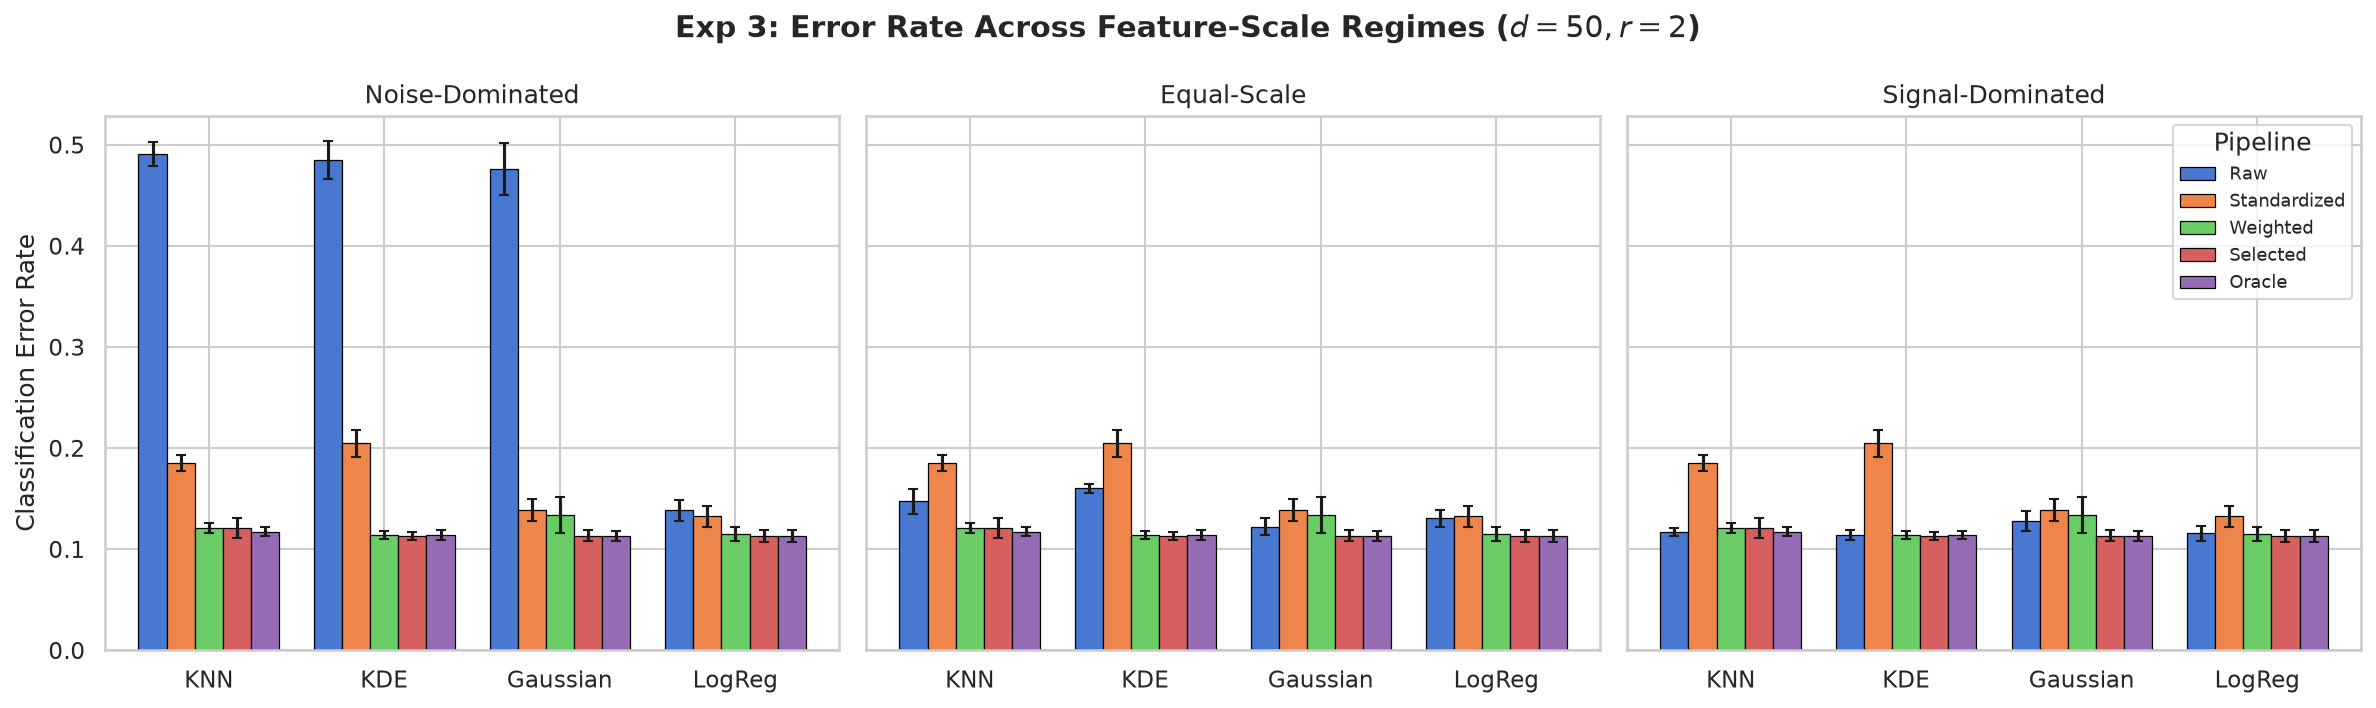

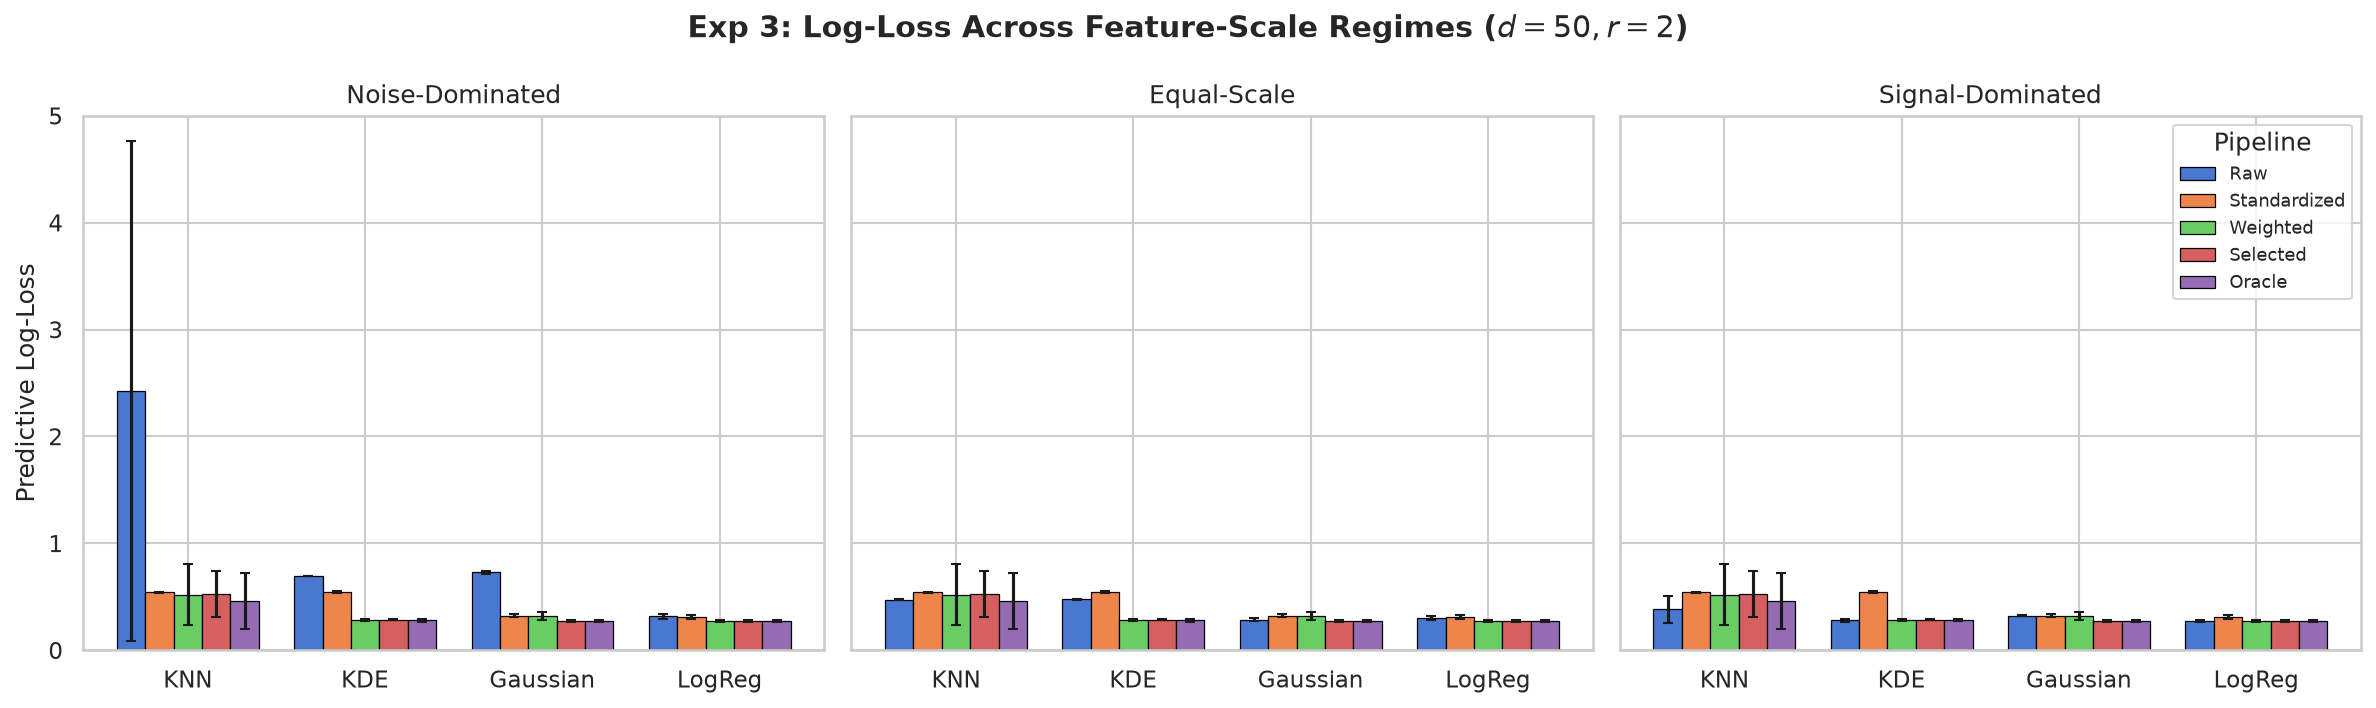

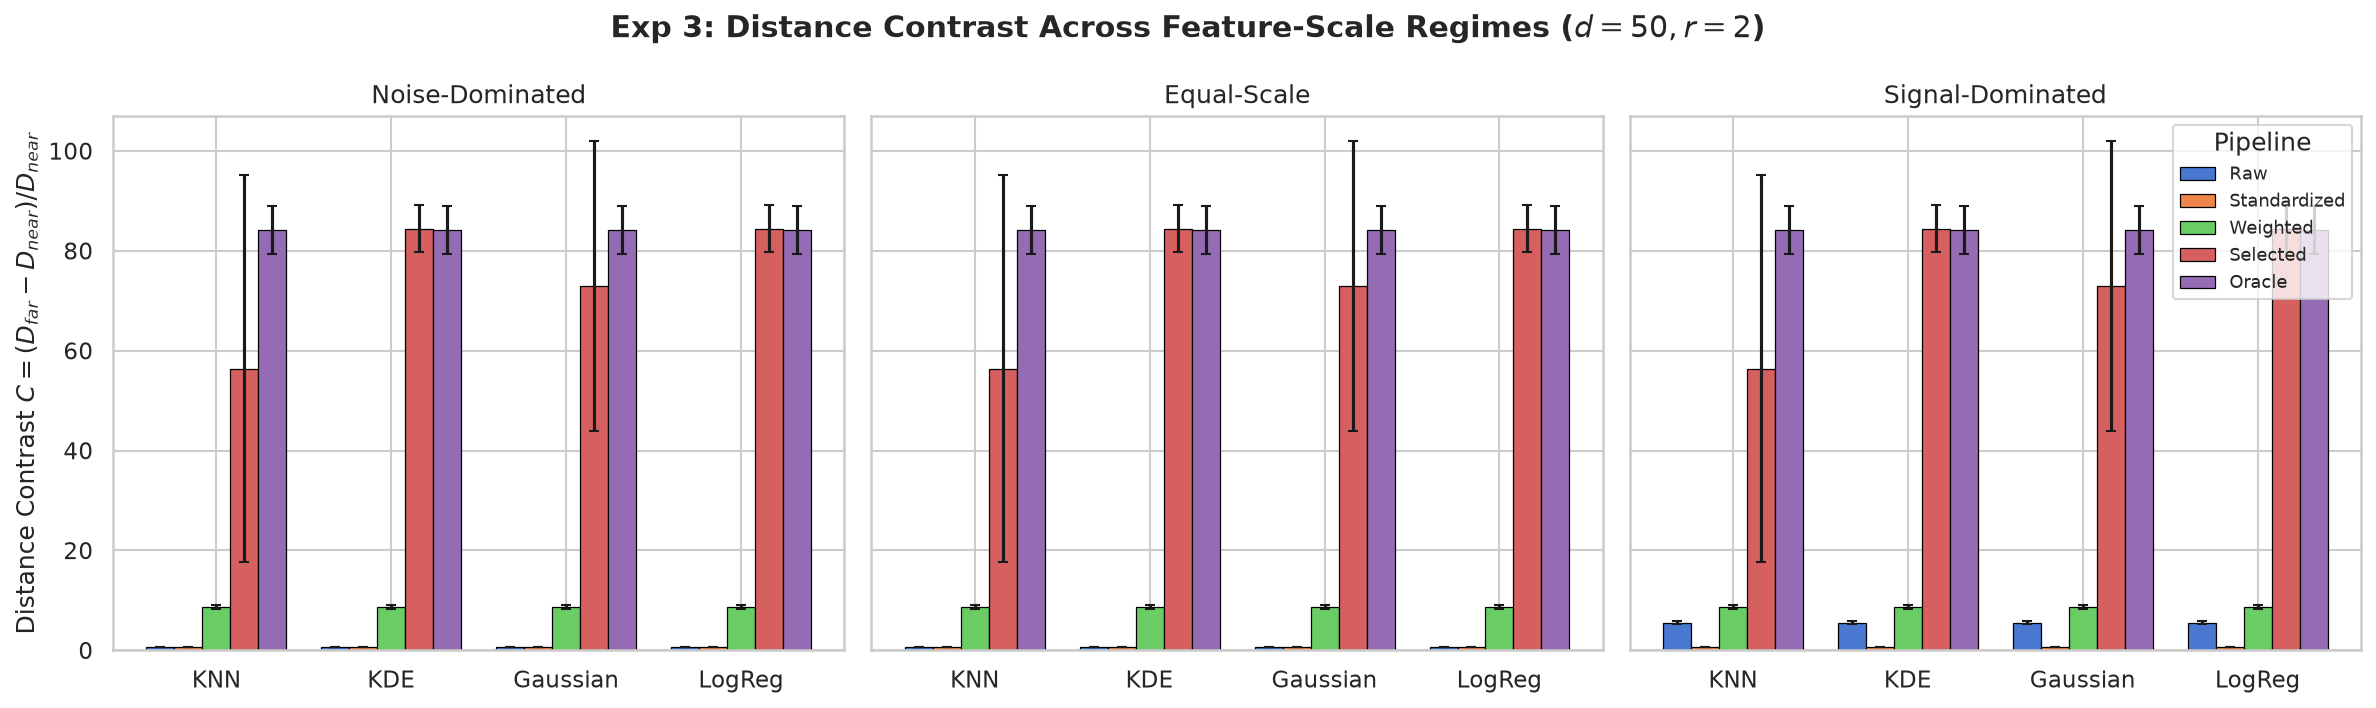

In [12]:
plot_scale_regimes(
    exp3_summary, "error_rate_mean", "error_rate_std",
    y_label="Classification Error Rate",
    title="Exp 3: Error Rate Across Feature-Scale Regimes ($d=50, r=2$)",
    save_path=os.path.join(plots_dir, "exp3_error_rate_comparison.png"),
)

plot_scale_regimes(
    exp3_summary, "log_loss_mean", "log_loss_std",
    y_label="Predictive Log-Loss",
    title="Exp 3: Log-Loss Across Feature-Scale Regimes ($d=50, r=2$)",
    save_path=os.path.join(plots_dir, "exp3_log_loss_comparison.png"),
)

plot_scale_regimes(
    exp3_summary, "mean_contrast_mean", "mean_contrast_std",
    y_label="Distance Contrast $C = (D_{far}-D_{near})/D_{near}$",
    title="Exp 3: Distance Contrast Across Feature-Scale Regimes ($d=50, r=2$)",
    save_path=os.path.join(plots_dir, "exp3_contrast_comparison.png"),
)

### Analysis
- **Noise-Dominated ($\sigma_z=1, \sigma_u=10$):** Raw KNN ($49.06\%$), KDE ($48.52\%$), and Gaussian ($47.64\%$) collapse to random guessing. Standardization cuts KNN/KDE error to $18.52\%$ / $20.48\%$ and restores Gaussian to $13.90\%$, though the 48 unit-variance noise features still hurt local models.
- **Equal-Scale ($\sigma_z=1, \sigma_u=1$):** Standardization slightly worsens KNN ($14.72\% \to 18.52\%$) and KDE ($16.02\% \to 20.48\%$) because dividing $z_j$ by $\sqrt{\sigma_z^2 + \delta^2} \approx 1.31$ shrinks the signal relative to noise.
- **Signal-Dominated ($\sigma_z=10, \sigma_u=1$):** Raw KNN ($11.72\%$) and Raw KDE ($11.44\%$) already match the Oracle because signal dominates distance. Standardization amplifies the 48 noise coordinates to unit variance, pushing KNN to $18.52\%$ and KDE to $20.48\%$.
- **Weighted & Selected:** Training-only ANOVA weighting and feature selection achieve $11.32\%$–$12.10\%$ error across all three regimes and restore contrast from $C \approx 0.71$ to $8.74$ (`Weighted`) and $56.3$–$84.4$ (`Selected`), matching the Oracle.

## 8. Experiment 4: Informative Dimension ($r$) vs. Ambient Dimension ($d$)
Fixed: $n_{\text{train}} = 500$, $n_{\text{val}} = 500$, $n_{\text{test}} = 1000$, $\mu_0 = 1.2$ (constant Bayes error $11.51\%$) over 5 seeds.
Varied: $r \in \{1, 2, 4, 8, 16, 32\}$ under Fixed Ambient ($d = 50$) and No Noise ($d = r$).

In [13]:
t0 = time.time()
r_list = [1, 2, 4, 8, 16, 32]
n_train_4, n_val_4, n_test_4 = 500, 500, 1000

modes = [
    ("Fixed Ambient (d=50)", lambda r: 50),
    ("No Noise (d=r)", lambda r: r),
]

rows_exp4 = []
for mode_name, get_d in modes:
    for r in r_list:
        d = get_d(r)
        for s in range(N_SEEDS):
            seed = 42 + s
            X_tr, y_tr, X_va, y_va, X_te, y_te = generate_splits(
                n_train_4, n_val_4, n_test_4, d=d, r=r, signal_norm=SIGNAL_NORM, seed=seed
            )
            dist_metrics = compute_distance_metrics(X_te, X_tr)

            for clf in CLASSIFIERS:
                res = evaluate_classifier(clf, X_tr, y_tr, X_va, y_va, X_te, y_te, dist_metrics)
                res.update({"mode": mode_name, "r": r, "d": d, "seed": seed})
                rows_exp4.append(res)

exp4_raw = pd.DataFrame(rows_exp4)
exp4_summary = summarize_results(exp4_raw, ["mode", "r", "classifier"])
save_results(exp4_raw, exp4_summary, "experiment_4_informative_dimension", RESULTS_DIR)

print(f"Experiment 4 finished in {time.time() - t0:.1f}s")
display(format_compact_table(exp4_summary, ["mode", "r", "classifier"]))

Experiment 4 finished in 23.9s


,mode,r,classifier,Error (Mean ± Std),Log-Loss (Mean ± Std),D_near,D_far,Contrast C
0,Fixed Ambient (d=50),1,Gaussian,0.1230 ± 0.0044,0.2864 ± 0.0015,7.471,12.858,0.726
1,Fixed Ambient (d=50),1,GaussianKDE,0.1688 ± 0.0137,0.4893 ± 0.0074,7.471,12.858,0.726
2,Fixed Ambient (d=50),1,KNN,0.1598 ± 0.0074,0.4815 ± 0.0109,7.471,12.858,0.726
3,Fixed Ambient (d=50),1,LogisticRegression,0.1324 ± 0.0050,0.3101 ± 0.0052,7.471,12.858,0.726
4,Fixed Ambient (d=50),2,Gaussian,0.1222 ± 0.0082,0.2863 ± 0.0112,7.477,12.863,0.725
5,Fixed Ambient (d=50),2,GaussianKDE,0.1602 ± 0.0046,0.4767 ± 0.0025,7.477,12.863,0.725
6,Fixed Ambient (d=50),2,KNN,0.1472 ± 0.0122,0.4727 ± 0.0027,7.477,12.863,0.725
7,Fixed Ambient (d=50),2,LogisticRegression,0.1306 ± 0.0083,0.3020 ± 0.0150,7.477,12.863,0.725
8,Fixed Ambient (d=50),4,Gaussian,0.1140 ± 0.0147,0.2713 ± 0.0218,7.494,12.876,0.723
9,Fixed Ambient (d=50),4,GaussianKDE,0.1432 ± 0.0110,0.4716 ± 0.0074,7.494,12.876,0.723


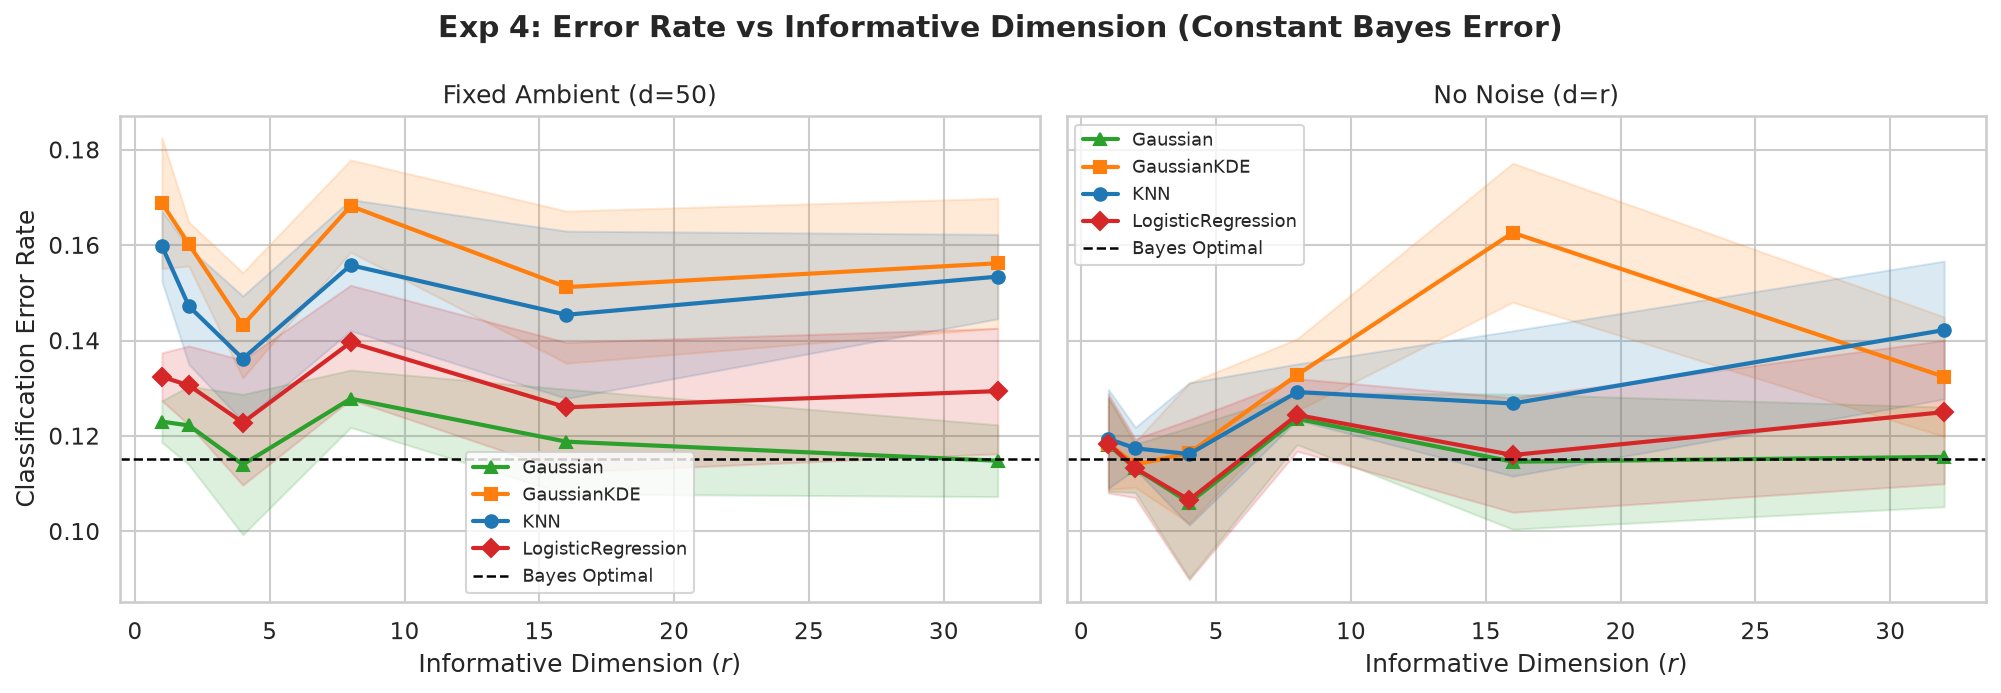

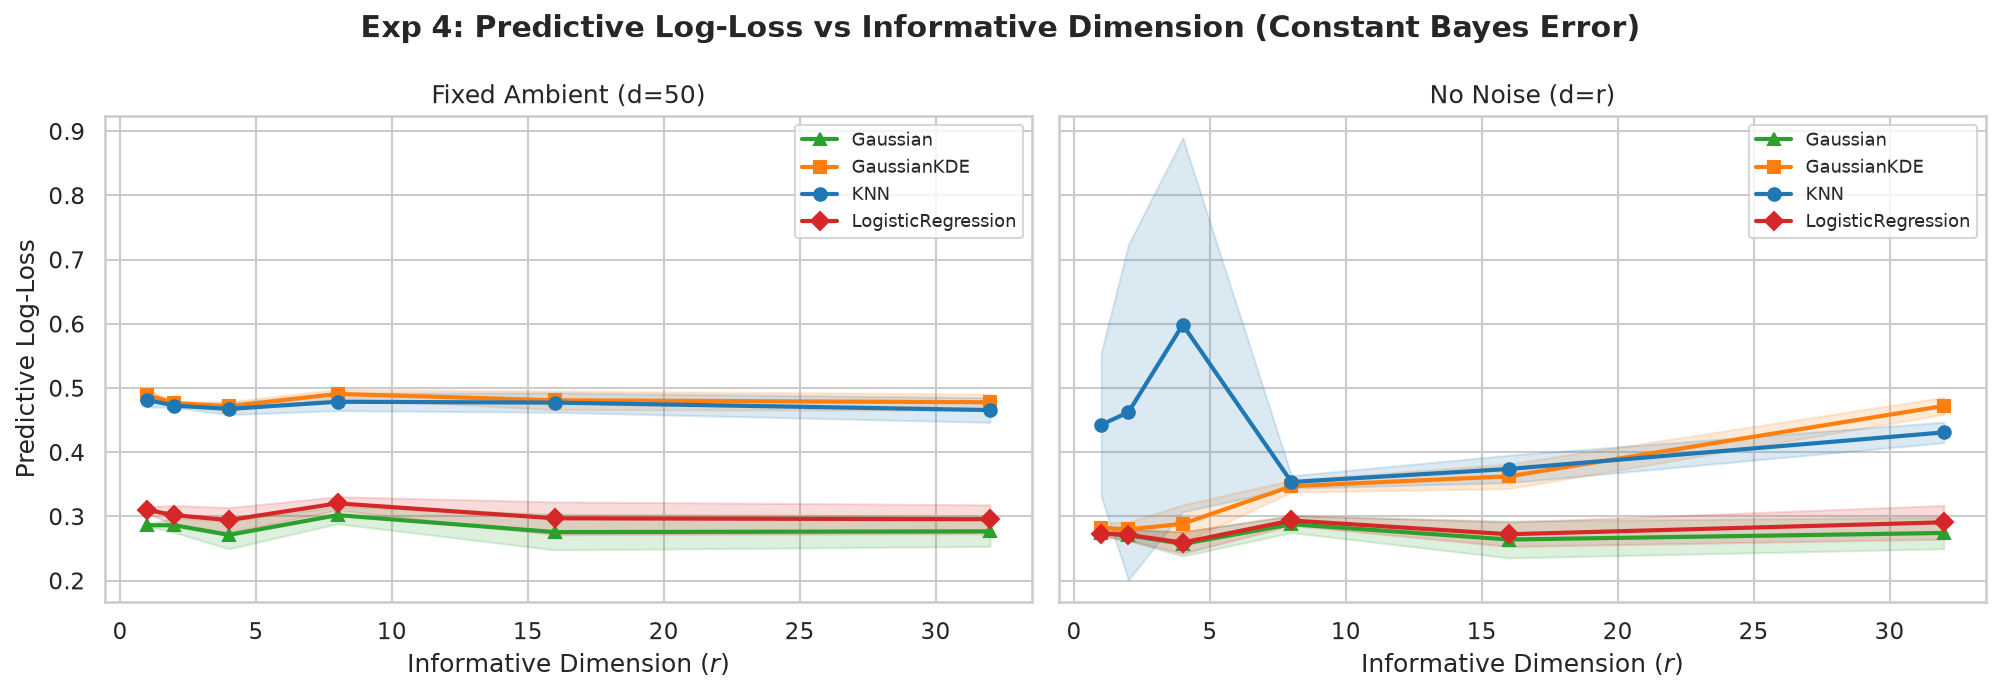

In [14]:
plot_paired_informative_dim(
    exp4_summary, "error_rate_mean", "error_rate_std",
    y_label="Classification Error Rate",
    title="Exp 4: Error Rate vs Informative Dimension (Constant Bayes Error)",
    save_path=os.path.join(plots_dir, "exp4_error_vs_informative_dim.png"),
    hline=BAYES_ERROR,
)

plot_paired_informative_dim(
    exp4_summary, "log_loss_mean", "log_loss_std",
    y_label="Predictive Log-Loss",
    title="Exp 4: Predictive Log-Loss vs Informative Dimension (Constant Bayes Error)",
    save_path=os.path.join(plots_dir, "exp4_log_loss_vs_informative_dim.png"),
)

### Analysis
- **Fixed Ambient ($d = 50$):** With total dimension $d = 50$ and total separation $2\mu_0 = 2.4$ held constant, contrast stays around $C \approx 0.72$ and error rates remain roughly flat from $r=1$ to $r=32$ (KNN $\approx 15\%$, KDE $\approx 16\%$, Gaussian $\approx 12\%$, LogReg $\approx 13\%$).
- **No Noise ($d = r$):** Even without irrelevant variables, spreading the same signal across $r = 1 \to 32$ coordinates drops contrast from $10017.0$ to $0.987$, raises KNN error from $11.94\%$ to $14.22\%$, and increases KDE log-loss from $0.283$ to $0.472$.
- For distance-based methods, degradation depends on total dimensionality $d$ relative to $n$ and total separation $\mu_0$, whether extra dimensions are pure noise or diluted signal.

## 9. Summary
- **Ambient dimension (Exp 1):** Increasing $d$ from $2$ to $200$ collapses contrast $C$ ($84.15 \to 0.305$) and raises KNN/KDE error to $21.68\%$ / $22.98\%$, while Regularized Gaussian ($14.00\%$) and L2 Logistic Regression ($15.34\%$) stay much closer to the $11.51\%$ Bayes floor.
- **Sample size (Exp 2):** Scaling $n_{\text{train}}$ from $100$ to $5000$ at $d=50$ brings Gaussian ($11.46\%$) and Logistic Regression ($11.74\%$) to the Bayes floor, while KNN ($14.02\%$) and KDE (log-loss $0.472$) improve very slowly.
- **Feature scales (Exp 3):** Standardization helps in the Noise-Dominated regime ($49.06\% \to 18.52\%$ for KNN), slightly hurts Equal-Scale ($14.72\% \to 18.52\%$), and hurts Signal-Dominated ($11.72\% \to 18.52\%$). Supervised ANOVA weighting and selection match the Oracle ($11.32\%$–$12.10\%$) in all three regimes.
- **Informative vs. ambient dimension (Exp 4):** Under Fixed Ambient ($d=50$), performance is nearly flat across $r \in [1, 32]$; under No Noise ($d=r$), increasing $r$ still collapses contrast ($10017.0 \to 0.987$) and degrades KNN and KDE.